In [10]:
import time
import os
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

%matplotlib inline

from sklearn.model_selection import RandomizedSearchCV
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from xgboost import XGBRegressor

# Load processed data from T04

data_dir = "../../Feature Engineering/data_processed"

data_train = pd.read_csv(
    os.path.join(data_dir, "data_train.csv")
)

data_test = pd.read_csv(
    os.path.join(data_dir, "data_test.csv")
)

print("Train shape:", data_train.shape)
print("Test shape:", data_test.shape)



Train shape: (9995, 135)
Test shape: (2499, 135)


In [11]:
# Separate features and target

target = "price_million"

X_train = data_train.drop(columns=[target])
y_train = data_train[target]

X_test = data_test.drop(columns=[target])
y_test = data_test[target]

# Validate feature consistency

assert list(X_train.columns) == list(X_test.columns), \
    "Train and test features do not match!"

assert not X_train.isna().any().any(), \
    "Training data contains missing values!"

assert not X_test.isna().any().any(), \
    "Testing data contains missing values!"

assert (y_train >= 0).all(), \
    "Training target contains negative prices!"

assert (y_test >= 0).all(), \
    "Testing target contains negative prices!"

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nMissing values:")
print("Train:", X_train.isna().sum().sum())
print("Test:", X_test.isna().sum().sum())

print("\nTarget statistics:")
print(y_train.describe())
non_numeric = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

assert len(non_numeric) == 0, \
    f"Non-numeric features found: {non_numeric}"

assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_test.to_numpy()).all()
assert np.isfinite(y_train.to_numpy()).all()
assert np.isfinite(y_test.to_numpy()).all()

print("Data validation passed!")

X_train: (9995, 134)
X_test: (2499, 134)

Missing values:
Train: 0
Test: 0

Target statistics:
count     9995.000000
mean       513.155361
std        390.178024
min         20.000000
25%        278.000000
50%        435.000000
75%        635.000000
max      10900.000000
Name: price_million, dtype: float64
Data validation passed!


In [12]:
# Baseline Random Forest

rf = TransformedTargetRegressor(
    regressor=RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    func=np.log1p,
    inverse_func=np.expm1
)

rf.fit(X_train, y_train)

pred_rf = rf.predict(X_test)

rf_rmse = np.sqrt(mean_squared_error(y_test, pred_rf))
rf_mae = mean_absolute_error(y_test, pred_rf)
rf_r2 = r2_score(y_test, pred_rf)

print("Random Forest Baseline")
print("RMSE:", round(rf_rmse, 1), "million VND")
print("MAE :", round(rf_mae, 1), "million VND")
print("R2  :", round(rf_r2, 3))

Random Forest Baseline
RMSE: 216.2 million VND
MAE : 83.1 million VND
R2  : 0.733


In [13]:
# Baseline XGBoost

xgb = TransformedTargetRegressor(
    regressor=XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        random_state=42,
        n_jobs=-1
    ),
    func=np.log1p,
    inverse_func=np.expm1
)

xgb.fit(X_train, y_train)

pred_xgb = xgb.predict(X_test)

xgb_rmse = np.sqrt(mean_squared_error(y_test, pred_xgb))
xgb_mae = mean_absolute_error(y_test, pred_xgb)
xgb_r2 = r2_score(y_test, pred_xgb)

print("XGBoost Baseline")
print("RMSE:", round(xgb_rmse, 1), "million VND")
print("MAE :", round(xgb_mae, 1), "million VND")
print("R2  :", round(xgb_r2, 3))

XGBoost Baseline
RMSE: 214.0 million VND
MAE : 84.7 million VND
R2  : 0.739


In [14]:
# Hyperparameter tuning

searches = {
    "rf": (
        TransformedTargetRegressor(
            regressor=RandomForestRegressor(
                random_state=42,
                n_jobs=-1
            ),
            func=np.log1p,
            inverse_func=np.expm1
        ),
        {
            "regressor__n_estimators": [200, 400, 600],
            "regressor__max_depth": [None, 15, 25],
            "regressor__min_samples_leaf": [1, 2, 4],
            "regressor__max_features": ["sqrt", 0.5, 1.0]
        }
    ),

    "xgb": (
        TransformedTargetRegressor(
            regressor=XGBRegressor(
                random_state=42,
                n_jobs=-1
            ),
            func=np.log1p,
            inverse_func=np.expm1
        ),
        {
            "regressor__n_estimators": [300, 600, 900],
            "regressor__learning_rate": [0.03, 0.05, 0.1],
            "regressor__max_depth": [4, 6, 8],
            "regressor__subsample": [0.7, 0.9, 1.0],
            "regressor__colsample_bytree": [0.5, 0.8, 1.0]
        }
    )
}

best = {}
tuning_results = {}

for name, (estimator, params) in searches.items():

    print(f"\nTuning {name.upper()}...")

    start_time = time.time()

    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=params,
        n_iter=10,
        cv=3,
        scoring="neg_root_mean_squared_error",
        random_state=42,
        n_jobs=1,
        verbose=1
    )

    search.fit(X_train, y_train)

    best[name] = search.best_estimator_

    tuning_time = (time.time() - start_time) / 60

    tuning_results[name] = {
        "Best Parameters": search.best_params_,
        "CV RMSE": -search.best_score_,
        "Time (minutes)": tuning_time
    }

    print("\nBest parameters:")
    print(search.best_params_)

    print("CV RMSE:", round(-search.best_score_, 2))
    print("Time:", round(tuning_time, 2), "minutes")


Tuning RF...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best parameters:
{'regressor__n_estimators': 200, 'regressor__min_samples_leaf': 1, 'regressor__max_features': 1.0, 'regressor__max_depth': None}
CV RMSE: 211.43
Time: 0.52 minutes

Tuning XGB...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best parameters:
{'regressor__subsample': 0.9, 'regressor__n_estimators': 600, 'regressor__max_depth': 8, 'regressor__learning_rate': 0.1, 'regressor__colsample_bytree': 1.0}
CV RMSE: 206.34
Time: 0.5 minutes


In [15]:
# Evaluate tuned models on the test set

tuned_predictions = {}
tuned_metrics = {}

for name, model in best.items():

    pred = model.predict(X_test)

    tuned_predictions[name] = pred

    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)

    tuned_metrics[name] = {
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }

    print(f"\n{name.upper()} Tuned")
    print("RMSE:", round(rmse, 1), "million VND")
    print("MAE :", round(mae, 1), "million VND")
    print("R2  :", round(r2, 3))


RF Tuned
RMSE: 216.2 million VND
MAE : 83.1 million VND
R2  : 0.733

XGB Tuned
RMSE: 205.2 million VND
MAE : 79.2 million VND
R2  : 0.76


In [16]:
# Compare baseline and tuned models

results = [
    {
        "Model": "Random Forest (baseline)",
        "RMSE": rf_rmse,
        "MAE": rf_mae,
        "R2": rf_r2
    },
    {
        "Model": "Random Forest (tuned)",
        "RMSE": tuned_metrics["rf"]["RMSE"],
        "MAE": tuned_metrics["rf"]["MAE"],
        "R2": tuned_metrics["rf"]["R2"]
    },
    {
        "Model": "XGBoost (baseline)",
        "RMSE": xgb_rmse,
        "MAE": xgb_mae,
        "R2": xgb_r2
    },
    {
        "Model": "XGBoost (tuned)",
        "RMSE": tuned_metrics["xgb"]["RMSE"],
        "MAE": tuned_metrics["xgb"]["MAE"],
        "R2": tuned_metrics["xgb"]["R2"]
    }
]

results_df = pd.DataFrame(results)

print(results_df.round(3).to_string(index=False))

                   Model    RMSE    MAE    R2
Random Forest (baseline) 216.190 83.099 0.733
   Random Forest (tuned) 216.190 83.099 0.733
      XGBoost (baseline) 213.970 84.677 0.739
         XGBoost (tuned) 205.187 79.205 0.760


In [17]:
# Select the best tuned model based on CV RMSE

best_name = min(
    tuning_results,
    key=lambda name: tuning_results[name]["CV RMSE"]
)

best_model = best[best_name]

print("Selected model:", best_name.upper())
print("CV RMSE:", round(tuning_results[best_name]["CV RMSE"], 2))
print("Best parameters:")
print(tuning_results[best_name]["Best Parameters"])

# Save selected model

joblib.dump(best_model, "best_model.pkl")

print("\nModel saved as best_model.pkl")

Selected model: XGB
CV RMSE: 206.34
Best parameters:
{'regressor__subsample': 0.9, 'regressor__n_estimators': 600, 'regressor__max_depth': 8, 'regressor__learning_rate': 0.1, 'regressor__colsample_bytree': 1.0}

Model saved as best_model.pkl


In [18]:
# T08: Model Interpretation & Error Analysis

from sklearn.metrics import mean_squared_error

# Confirm that the selected model is XGBoost
assert best_name == "xgb", "Selected model is not XGBoost!"

# Reuse the selected model and existing test data
assert best_model is best["xgb"]
assert X_test.shape[0] == y_test.shape[0]

# Generate predictions using the selected model
y_pred = best_model.predict(X_test)

# Calculate residuals
residuals = y_test - y_pred
abs_errors = residuals.abs()

# Calculate evaluation metrics
t08_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
t08_mae = mean_absolute_error(y_test, y_pred)
t08_r2 = r2_score(y_test, y_pred)

print("T08 - Selected Model:", best_name.upper())
print("RMSE:", round(t08_rmse, 3), "million VND")
print("MAE :", round(t08_mae, 3), "million VND")
print("R2  :", round(t08_r2, 3))
print("Test samples:", len(y_test))

T08 - Selected Model: XGB
RMSE: 205.187 million VND
MAE : 79.205 million VND
R2  : 0.76
Test samples: 2499


Residual Statistics:
Mean residual: 19.0
Median residual: 1.8
Mean absolute residual: 79.21


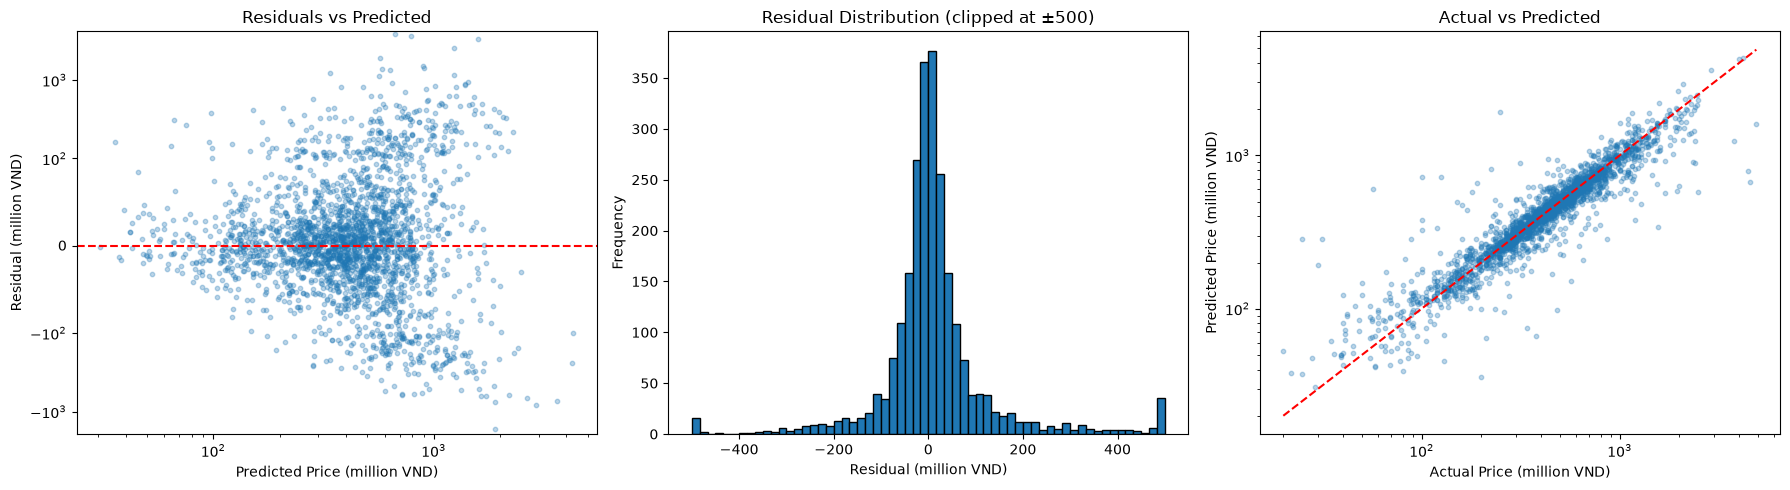

In [19]:
# Calculate residual statistics
print("Residual Statistics:")
print("Mean residual:", round(residuals.mean(), 2))
print("Median residual:", round(residuals.median(), 2))
print("Mean absolute residual:", round(abs_errors.mean(), 2))

# Visualize residuals
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# 1. Residuals vs Predicted
ax[0].scatter(y_pred, residuals, alpha=0.3, s=10)
ax[0].axhline(0, color="red", linestyle="--")
ax[0].set_xscale("log")
ax[0].set_yscale("symlog", linthresh=100)
ax[0].set_title("Residuals vs Predicted")
ax[0].set_xlabel("Predicted Price (million VND)")
ax[0].set_ylabel("Residual (million VND)")

# 2. Residual Distribution
ax[1].hist(
    residuals.clip(-500, 500),
    bins=60,
    edgecolor="black"
)
ax[1].set_title("Residual Distribution (clipped at ±500)")
ax[1].set_xlabel("Residual (million VND)")
ax[1].set_ylabel("Frequency")

# 3. Actual vs Predicted
ax[2].scatter(y_test, y_pred, alpha=0.3, s=10)

lim = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

ax[2].plot(lim, lim, color="red", linestyle="--")
ax[2].set_xscale("log")
ax[2].set_yscale("log")
ax[2].set_title("Actual vs Predicted")
ax[2].set_xlabel("Actual Price (million VND)")
ax[2].set_ylabel("Predicted Price (million VND)")

plt.tight_layout()
plt.show()

In [20]:
# Calculate percentage errors
residual_pct = residuals / y_test * 100

# Define price ranges
bins = [0, 200, 400, 700, 1000, np.inf]

labels = [
    "<200",
    "200-400",
    "400-700",
    "700-1000",
    ">1000"
]

price_band = pd.cut(
    y_test,
    bins=bins,
    labels=labels
)

# Group errors by actual price range
error_by_band = pd.DataFrame({
    "Price Band": price_band,
    "Absolute Error": abs_errors,
    "Percentage Error": residual_pct.abs(),
    "Residual": residuals
}).groupby("Price Band", observed=True).agg(
    Samples=("Absolute Error", "size"),
    MAE=("Absolute Error", "mean"),
    MAPE=("Percentage Error", "mean"),
    Mean_Residual=("Residual", "mean")
).round(2)

print("Error Analysis by Price Range:")
print(error_by_band)

Error Analysis by Price Range:
            Samples     MAE   MAPE  Mean_Residual
Price Band                                       
<200            372   39.73  42.11         -23.02
200-400         756   39.40  13.18          -6.52
400-700         849   55.64  10.52           1.81
700-1000        295  100.15  12.07          26.07
>1000           227  337.39  19.75         227.95


Built-in Feature Importance:
carmodel_grouped       0.4425
carbrand_grouped       0.3194
gearbox                0.0566
fuel                   0.0557
cartype                0.0551
car_age                0.0272
carorigin              0.0255
region_grouped         0.0119
flag_zin               0.0019
odo_km                 0.0016
km_per_year            0.0011
flag_chinh_chu         0.0011
flag_bao_duong_hang    0.0004
dtype: float32


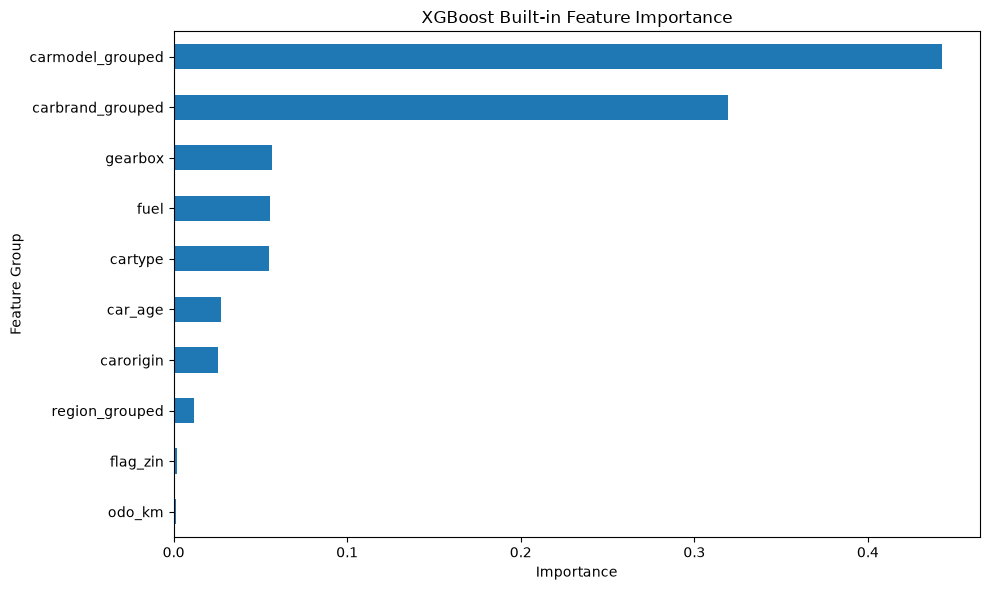

In [21]:
# Get feature importance from the selected XGBoost model
feature_importance = pd.Series(
    best_model.regressor_.feature_importances_,
    index=X_test.columns
)

# Group one-hot encoded categorical features
cat_prefixes = [
    "carbrand_grouped",
    "carmodel_grouped",
    "region_grouped",
    "gearbox",
    "fuel",
    "cartype",
    "carorigin"
]

def group_of(col):
    for prefix in cat_prefixes:
        if col.startswith(prefix + "_"):
            return prefix
    return col

# Aggregate importance by feature group
builtin_importance = (
    feature_importance
    .groupby(group_of)
    .sum()
    .sort_values(ascending=False)
)

print("Built-in Feature Importance:")
print(builtin_importance.head(15).round(4))

# Plot top 10 features
plt.figure(figsize=(10, 6))

builtin_importance.head(10).sort_values().plot(
    kind="barh"
)

plt.title("XGBoost Built-in Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature Group")
plt.tight_layout()
plt.show()

Grouped Permutation Importance:
carbrand_grouped       230.56
car_age                151.79
carmodel_grouped        73.21
gearbox                 44.56
odo_km                  26.42
cartype                 16.82
fuel                    15.05
km_per_year              9.69
region_grouped           6.27
carorigin                5.62
flag_chinh_chu           0.10
flag_zin                 0.08
flag_bao_duong_hang     -0.02
dtype: float64


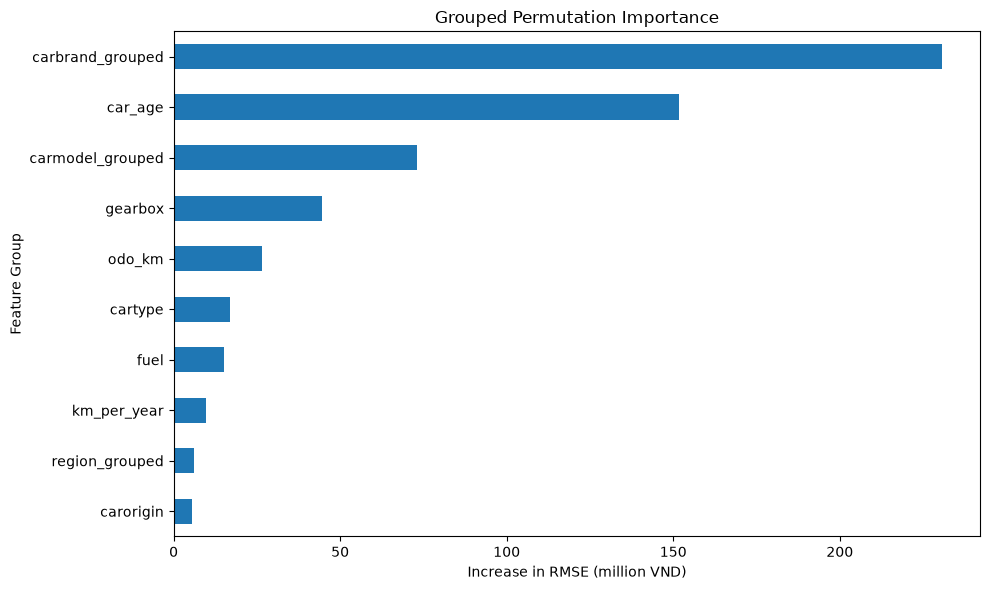

In [22]:
# Group columns by feature
groups = {}

for col in X_test.columns:
    group = group_of(col)
    groups.setdefault(group, []).append(col)

# Calculate baseline RMSE
base_rmse = np.sqrt(
    mean_squared_error(y_test, best_model.predict(X_test))
)

# Grouped permutation importance
rng = np.random.RandomState(42)

group_perm = {}

for group, cols in groups.items():

    scores = []

    for _ in range(5):

        X_permuted = X_test.copy()

        # Shuffle the entire feature group
        permutation = rng.permutation(len(X_permuted))

        X_permuted[cols] = (
            X_permuted[cols]
            .iloc[permutation]
            .to_numpy()
        )

        # Calculate RMSE increase
        permuted_pred = best_model.predict(X_permuted)

        permuted_rmse = np.sqrt(
            mean_squared_error(y_test, permuted_pred)
        )

        scores.append(permuted_rmse - base_rmse)

    group_perm[group] = np.mean(scores)

group_perm = pd.Series(group_perm).sort_values(
    ascending=False
)

print("Grouped Permutation Importance:")
print(group_perm.round(2))

# Visualize top 10 groups
plt.figure(figsize=(10, 6))

group_perm.head(10).sort_values().plot(
    kind="barh"
)

plt.title("Grouped Permutation Importance")
plt.xlabel("Increase in RMSE (million VND)")
plt.ylabel("Feature Group")

plt.tight_layout()
plt.show()

In [23]:
print("=" * 50)
print("T08 - FINAL MODEL ANALYSIS")
print("=" * 50)

print("\nSelected Model:", best_name.upper())

print("\nOverall Performance:")
print("RMSE:", round(t08_rmse, 2), "million VND")
print("MAE :", round(t08_mae, 2), "million VND")
print("R2  :", round(t08_r2, 3))

print("\nTop 5 Built-in Features:")
print(builtin_importance.head(5).round(4))

print("\nTop 5 Grouped Permutation Features:")
print(group_perm.head(5).round(2))

print("\nError by Price Range:")
print(error_by_band)

print("\nT08 Analysis Completed!")

T08 - FINAL MODEL ANALYSIS

Selected Model: XGB

Overall Performance:
RMSE: 205.19 million VND
MAE : 79.21 million VND
R2  : 0.76

Top 5 Built-in Features:
carmodel_grouped    0.4425
carbrand_grouped    0.3194
gearbox             0.0566
fuel                0.0557
cartype             0.0551
dtype: float32

Top 5 Grouped Permutation Features:
carbrand_grouped    230.56
car_age             151.79
carmodel_grouped     73.21
gearbox              44.56
odo_km               26.42
dtype: float64

Error by Price Range:
            Samples     MAE   MAPE  Mean_Residual
Price Band                                       
<200            372   39.73  42.11         -23.02
200-400         756   39.40  13.18          -6.52
400-700         849   55.64  10.52           1.81
700-1000        295  100.15  12.07          26.07
>1000           227  337.39  19.75         227.95

T08 Analysis Completed!
